In [1]:
import os
import glob
import sys
import json

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from ultralytics import YOLO
import numpy as np

sys.path.append("../../../gw_prototype")
from fisheye_camera import CameraCalibrationParameters, pixel2cm
from detection_area import CameraConfiguration, DetectionArea
from geometry import Point


In [2]:
BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe"
SUBSETS = ["train", "val", "holdout"]

In [3]:
WEIGHTS_PTH = \
    "/home/klymy/projects/researches/people_detection_pg2/results/cam3_revB_batch1_3_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/best.pt"
model = YOLO(WEIGHTS_PTH, task="pose")

In [4]:
preds = []
preds += model.predict(
    source=os.path.join(BASE_PTH, "images", "holdout"),
    task="pose",
    device=[2],
    batch=64,
    verbose=False,
    project=os.path.join(".", "predictions"),
    name="yolo",
    conf=0.2,
    iou=0.5,
)
preds += model.predict(
    source=os.path.join(BASE_PTH, "images", "val"),
    task="pose",
    device=[2],
    batch=64,
    verbose=False,
    project=os.path.join(".", "predictions"),
    name="yolo",
    conf=0.2,
    iou=0.5,
)
preds += model.predict(
    source=os.path.join(BASE_PTH, "images", "train"),
    task="pose",
    device=[2],
    batch=64,
    verbose=False,
    project=os.path.join(".", "predictions"),
    name="yolo",
    conf=0.2,
    iou=0.5,
)
len(preds)

1600

In [5]:
pred_data = []
for pred in preds:
    name = os.path.basename(pred.path)
    try:
        sensor_height = int(name.replace("_cam_", "").split("_H")[-1].split("_")[0])
    except ValueError:
        print(f"Skipping {name} due to ValueError")
        continue
    
    if pred.keypoints.xyn.shape[1] == 0:
        continue
    keypoints = pred.keypoints.xyn.cpu().numpy().squeeze(axis=1)
    
    for keypoint in keypoints:
        pred_data.append({
            "file_name": name,
            "x": keypoint[0],
            "y": keypoint[1],
            "sensor_height": sensor_height,
        })

pred_data_df = pd.DataFrame(pred_data)
pred_data_df.head()

Skipping 4.2_batch3____4.2_H_cam___11.jpg due to ValueError
Skipping 4.2_batch3____4.2_H_cam___12.jpg due to ValueError


,file_name,x,y,sensor_height
0,4.2_batch1____4.2_H260_me_2.jpg,0.303441,0.484607,260
1,4.2_batch1____4.2_H260_me_2.jpg,0.551584,0.709737,260
2,4.2_batch1____4.2_H260_me_2.jpg,0.224608,0.810738,260
3,4.2_batch1____4.2_H260_me_2.jpg,0.602119,0.356411,260
4,4.2_batch1____4.2_H260_me_2.jpg,0.742769,0.760276,260


In [6]:
label_paths = []
for subset in SUBSETS:
    subset_pth = os.path.join(BASE_PTH, "labels", subset)
    label_paths.extend(glob.glob(os.path.join(subset_pth, "*.txt")))

len(label_paths)

1600

In [7]:
data = []

W, H = 640, 480

for label_path in label_paths:
    name = os.path.basename(label_path)

    try:
        sensor_height = int(name.replace("_cam_", "").split("_H")[-1].split("_")[0])
    except ValueError:
        print(f"Skipping {name} due to ValueError")
        continue

    with open(label_path, "r") as f:
        lines = f.readlines()
    
    for line in lines:
        parts = line.strip().split()
        if len(parts) < 5:
            print(f"Skipping line in {name}: {line.strip()}")
            continue
        
        x = float(parts[-2])# * W
        y = float(parts[-1])# * H

        data.append({
            "file_name": name,
            "x": x,
            "y": y,
            "sensor_height": sensor_height
        })

df = pd.DataFrame(data)
df.head()

Skipping 4.2_batch3____4.2_H_cam___12.txt due to ValueError
Skipping 4.2_batch3____4.2_H_cam___11.txt due to ValueError


,file_name,x,y,sensor_height
0,4.2_batch3____4.2_H_cam_234_rivullis_75.txt,0.287453,0.807625,234
1,4.2_batch3____4.2_H_cam_234_rivullis_75.txt,0.116031,0.201708,234
2,4.2_batch3____4.2_H_cam_234_rivullis_75.txt,0.200937,0.814792,234
3,4.2_batch3____4.2_H_cam_234_rivullis_75.txt,0.151000,0.361104,234
4,4.2_batch3____4.2_H_cam_234_rivullis_75.txt,0.427500,0.186958,234


In [8]:
with open("../../../gw_prototype/camera_calibration/params/cam4_rev_b.json", "rt") as f:
    DATA = json.load(f)


CALIBRATION_PARAMS = CameraCalibrationParameters(
    DATA["LENS_PARAMS"]["CX"],
    DATA["LENS_PARAMS"]["CY"],
    DATA["LENS_PARAMS"]["FX"],
    DATA["LENS_PARAMS"]["FY"],
    DATA["LENS_PARAMS"]["K0"],
    DATA["LENS_PARAMS"]["K1"],
    DATA["LENS_PARAMS"]["K2"],
    DATA["LENS_PARAMS"]["K3"],
)


In [9]:
def calc_angle(df):
    angles = []
    for _, row in df.iterrows():
        x = row["x"] * W
        y = row["y"] * H
        sensor_height = row["sensor_height"]

        p = pixel2cm(Point(x, y), sensor_height, CALIBRATION_PARAMS)
        angle = np.rad2deg(np.arctan2(np.sqrt(p.x ** 2 + p.y ** 2), sensor_height))
        angles.append(angle)
        

    df["angle"] = angles


In [10]:
calc_angle(df)
calc_angle(pred_data_df)

In [11]:
pred_data_df.to_csv("predictions.csv", index=False)
df.to_csv("annotations.csv", index=False)

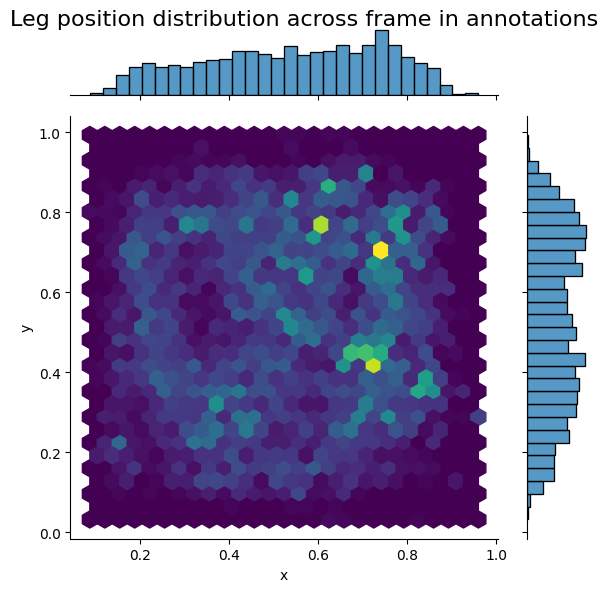

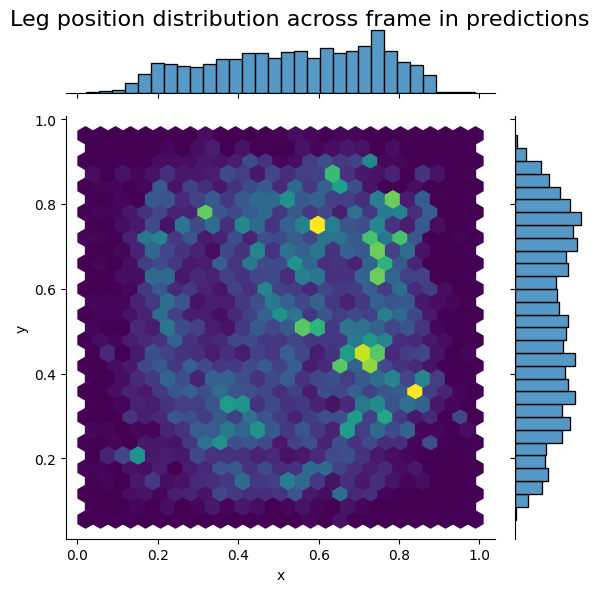

In [12]:
# Create the jointplot
g = sns.jointplot(
    data=df,
    x="x", y="y",
    kind="hex",      # "hex", "kde", or "hist"
    marginal_kws=dict(bins=30, fill=True),
    cmap="viridis",
)
# Add a title (adjust y position to avoid overlap)
g.fig.suptitle("Leg position distribution across frame in annotations", fontsize=16)
g.fig.tight_layout()      # Prevent overlap
g.fig.subplots_adjust(top=0.95)  # Adjust space for title

# Create the jointplot
g_pred = sns.jointplot(
    data=pred_data_df,
    x="x", y="y",
    kind="hex",      # "hex", "kde", or "hist"
    marginal_kws=dict(bins=30, fill=True),
    cmap="viridis",
)
# Add a title (adjust y position to avoid overlap)
g_pred.fig.suptitle("Leg position distribution across frame in predictions", fontsize=16)
g_pred.fig.tight_layout()      # Prevent overlap
g_pred.fig.subplots_adjust(top=0.95)  # Adjust space for title



In [13]:
pred_data_df["angle"].describe()

count    7293.000000
mean       30.707711
std        10.466313
min         0.401591
25%        24.807309
50%        31.960864
75%        38.201744
max        61.764459
Name: angle, dtype: float64

In [14]:
df["angle"].describe()

count    7263.000000
mean       30.418196
std        10.288982
min         0.917453
25%        24.411642
50%        31.679540
75%        37.945286
max        54.845586
Name: angle, dtype: float64

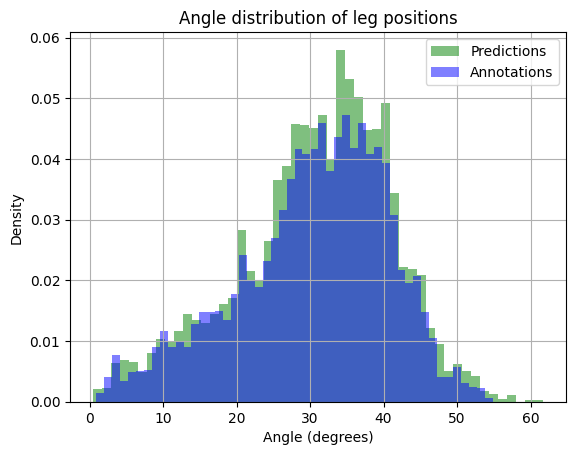

In [15]:
plt.hist(pred_data_df["angle"], bins=50, alpha=0.5, label="Predictions", color="green", \
    weights=np.zeros_like(pred_data_df["angle"]) + 1. / pred_data_df["angle"].size);
plt.hist(df["angle"], bins=50, alpha=0.5, label="Annotations", color="blue", \
    weights=np.zeros_like(df["angle"]) + 1. / df["angle"].size);

plt.grid()
plt.xlabel("Angle (degrees)")
plt.ylabel("Density")
plt.title("Angle distribution of leg positions")
plt.legend();

In [16]:
hist1, _, _ = np.histogram2d(df.x, df.y, bins=9, range=[[0, 1], [0, 1]])
hist2, _, _ = np.histogram2d(pred_data_df.x, pred_data_df.y, bins=9, range=[[0, 1], [0, 1]])

hist1 += 1e-6  # Avoid division by zero
hist2 += 1e-6  # Avoid division by zero
hist1 = hist1 / hist1.sum()  # Normalize to get density
hist2 = hist2 / hist2.sum()  # Normalize to get density

# Flatten and compare with chi2
from scipy.stats import chisquare
chi2_stat, p_value = chisquare(hist1.ravel(), hist2.ravel())

print(f"Chi-squared statistic: {chi2_stat}, p-value: {p_value}")

Chi-squared statistic: 2488.564739956956, p-value: 0.0


In [18]:
from scipy.stats import entropy

p = hist1.ravel() / hist1.sum()
q = hist2.ravel() / hist2.sum()

kl_div = entropy(p, q)  # KL(p || q)
print(f"KL divergence: {kl_div:.4f}")

kl_div = entropy(q, p)  # KL(q || p)
print(f"KL divergence reverse: {kl_div:.4f}")

KL divergence: 0.0194
KL divergence reverse: 0.0347
